In [13]:
# Import required libraries
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

# np.random.seed(42) sets NumPy’s random-number generator to a predictable starting point. That way, random values generated later (such as the MLP’s initial weights) are repeatable when you rerun the notebook. 42 is just an arbitrary seed value; using the same value gives the same sequence of random numbers.
np.random.seed(42)
print('Libraries imported successfully')

Libraries imported successfully


## Dataset Selection and Loading

In [3]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [34]:
import pandas as pd

# Load your dataset
df = pd.read_csv("/workspaces/Credit-card-fraud-detection/heart.csv")

# Dataset information
dataset_name = "Heart Failure Prediction Dataset"  
dataset_source = "Kaggle"  
n_samples = df.shape[0]     # Total number of rows
n_features = df.shape[1] - 1     # Number of features (excluding target)
problem_type = "binary_classification"  

print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Samples: {n_samples}, Features: {n_features}")
print(f"Problem Type: {problem_type}")

Dataset: Heart Failure Prediction Dataset
Source: Kaggle
Samples: 918, Features: 11
Problem Type: binary_classification


In [21]:
print(f"Features: {df.columns.tolist()}")

Features: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


## Data Preprocessing

In [22]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [23]:
# Select columns with object or category dtype
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

if categorical_cols:
    print("Categorical features found:")
    for col in categorical_cols:
        print(f"{col}")
else: 
    print("No categorical features found.")

Categorical features found:
Sex
ChestPainType
RestingECG
ExerciseAngina
ST_Slope


In [ ]:
# Preprocess your data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Handle missing values if any
if df.isnull().sum().sum() == 0:
    print("No missing values found")
else:
    features_with_nulls = df.columns[df.isnull().any()].tolist()
    print("Features with null values:", features_with_nulls)

target_col = "HeartDisease"

df = df.dropna(subset=[target_col])
X = df.drop(columns=[target_col])
y = df[target_col]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# The train_test_split function randomly shuffles the rows before dividing them into training and 
# testing sets. If you set random_state=42, the same shuffle order is produced every time you run 
# the code, so the split is reproducible.

numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # Replace missing values with the median of the column.
    ("scaler", StandardScaler()) # To standardize each column: it subtracts the column’s mean and divides by its standard deviation.
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")), # Replace missing values with the most frequent value of the column.
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)) # Converts categorical data (text or categories) into numerical columns.
])

# ColumnTransformer applies the existing numeric_pipeline to the columns listed in numeric_cols and the categorical pipeline to those in categorical_cols, then combines the results.
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

X_train = preprocessor.fit_transform(X_train) # fit_transform(X_train) learns imputation values, category levels, and scaling statistics from the training data, and transforms it.
X_test = preprocessor.transform(X_test) # transform(X_test) applies those same learned settings to the test data without fitting again, helping avoid data leakage from the test set.

train_samples = X_train.shape[0]
test_samples = X_test.shape[0]
train_test_ratio = train_samples / (train_samples + test_samples)


train_samples = X_train.shape[0]       # Number of training samples
test_samples = X_test.shape[0]        # Number of test samples
train_test_ratio = 0.8  # 0.8 for 80-20 split

No missing values found


##### OneHotEncoder

Converts categorical data (text or categories) into numerical columns.

* handle_unknown="ignore"

Suppose the encoder is trained on these categories, Red, Blue, Green. Later, it encounters a new category called Yellow in test data. Since Yellow was not present during training, the encoder doesn't know it as a learned category. With handle_unknown="ignore", the encoder does not throw an error. Instead, it represents the unseen category with zeros across the encoded columns.

* sparse_output=False

With sparse_output=False: the encoder returns a regular, dense NumPy array.

With sparse_output=True: the encoder returns a sparse matrix, which stores data more efficiently when most values are zero.

##### fit_transform()

fit_transform combines two actions: fit learns preprocessing details from the data, and transform applies them.

Why only transform() for test data?

If you run preprocessor.fit_transform(X_test), it relearns the medians, means, most-frequent categories, and one-hot-encoding categories from the test data itself, then transforms it. That means test rows may be represented differently from training rows—for example, numeric values get scaled with different means and standard deviations, and the encoded columns may differ if the test set has different categories. This is called data leakage. So we fit once on training data; only transform the test data.

In [25]:
print(f"Train samples: {train_samples}")
print(f"Test samples: {test_samples}")
print(f"Split ratio: {train_test_ratio:.1%}")

Train samples: 734
Test samples: 184
Split ratio: 80.0%


## Baseline Model Implementation

In [26]:
class BaselineModel:
    """
    Baseline linear model with gradient descent
    Implement: Logistic Regression
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def fit(self, X, y):
        """
        Implement gradient descent training
        
        Steps:
        1. Initialize weights and bias
        2. For each iteration:
           a. Compute predictions (forward pass)
           b. Compute loss
           c. Compute gradients
           d. Update weights and bias
           e. Store loss in self.loss_history
        
        Must populate self.loss_history with loss at each iteration!
        """
        n_samples, n_features = X.shape
        
        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        # Implement gradient descent loop
        for i in range(self.n_iterations):
            # 1. Forward pass: y_pred = ...
            linear_output = np.dot(X, self.weights) + self.bias
            y_pred = self.sigmoid(linear_output)
            
            # 2. Compute loss
            loss = -np.mean(
                y * np.log(y_pred + 1e-9) + (1 - y) * np.log(1 - y_pred + 1e-9)
            )
            
            # 3. Compute gradients: dw = ..., db = ...
            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)
            
            # 4. Update: self.weights -= self.lr * dw
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
            # 5. self.loss_history.append(loss)
            self.loss_history.append(loss)
        
        return self
    
    def predict(self, X):
        """
        Implement prediction
        
        For classification: return class probabilities or labels
        """
        linear_output = np.dot(X, self.weights) + self.bias
        probabilities = self.sigmoid(linear_output)

        # Produces True for probabilities at least 0.5 and False for probabilities below 0.5.
        return (probabilities >= 0.5).astype(int)

print("Baseline model class defined")

Baseline model class defined


Sigmoid function

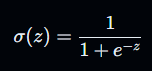

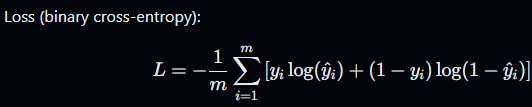 

where m=number of training samples 

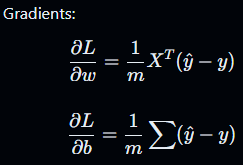

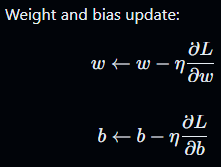

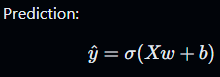

In [27]:
# Train baseline model
print("Training baseline model...")
baseline_start_time = time.time()

# Initialize and train your baseline model
baseline_model = BaselineModel(learning_rate=0.01, n_iterations=1000)
baseline_model.fit(X_train, y_train.values)

# Make predictions
baseline_predictions = baseline_model.predict(X_test)

baseline_training_time = time.time() - baseline_start_time
print(f"Baseline training completed in {baseline_training_time:.2f}s")
print(f"Loss decreased from {baseline_model.loss_history[0]:.4f} to {baseline_model.loss_history[-1]:.4f}")

Training baseline model...
Baseline training completed in 0.10s
Loss decreased from 0.6931 to 0.3626


## Multi-Layer Perceptron Implementation

In [28]:
class MLP:
    """
    Multi-Layer Perceptron implemented from scratch and trains it using gradient descent.
    """
    def __init__(self, architecture, learning_rate=0.01, n_iterations=1000):
        """
        architecture: list [input_size, hidden1, hidden2, ..., output_size]
        [30, 32, 16, 1] means:
            - 30 input features
            - Hidden layer 1: 32 neurons (ReLU activation)
            - Hidden layer 2: 16 neurons (ReLU activation)
            - Output layer: 1 output neuron that predicts the probability of malignancy (sigmoid activation)
        """
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.parameters = {}
        self.loss_history = []
        self.cache = {}
    
    def initialize_parameters(self):
        """
        Initialize weights and biases for all layers
        
        For each layer l:
        - W[l]: weight matrix of shape (n[l], n[l-1])
        - b[l]: bias vector of shape (n[l], 1)
        
        Store in self.parameters dictionary
        """
        np.random.seed(42)
        
        for l in range(1, len(self.architecture)):
            # weight initialization using He initialization for ReLU
            # The weights are randomly initialized. 
            # The scaling factor sqrt{2/n} is called He initialization. It is commonly used with ReLU hidden layers to help keep activation magnitudes stable.
            self.parameters[f'W{l}'] = np.random.randn(self.architecture[l-1], self.architecture[l]) * np.sqrt(2.0 / self.architecture[l-1])
            # bias initialization to zeros
            self.parameters[f'b{l}'] = np.zeros((1, self.architecture[l]))
 
    def relu(self, Z):
        """ReLU activation function"""
        return np.maximum(0, Z)
    
    def relu_derivative(self, Z):
        """ReLU derivative"""
        return (Z > 0).astype(float)
    
    def sigmoid(self, Z):
        """Sigmoid activation (for binary classification output)"""
        return 1 / (1 + np.exp(-np.clip(Z, -500, 500)))
    
    def forward_propagation(self, X):
        """
        Implement forward pass through all layers
        
        For each layer:
        1. Z[l] = A[l-1] * W[l] + b[l]
        2. A[l] = activation(Z[l])
        
        Store Z and A in self.cache for backpropagation
        Return final activation A[L]
        """
        self.cache['A0'] = X
        L = len(self.architecture) - 1
        
        # Hidden Layers
        for l in range(1, L):
            Z = (
                np.dot(
                    self.cache[f'A{l-1}'], self.parameters[f'W{l}']
                ) + self.parameters[f'b{l}']
            )
            A = self.relu(Z)
            self.cache[f'Z{l}'] = Z
            self.cache[f'A{l}'] = A

        # Output Layer
        ZL = (
            np.dot( self.cache[f'A{L-1}'], self.parameters[f'W{L}'] ) + self.parameters[f'b{L}']
        )
        AL = self.sigmoid(ZL)

        self.cache[f'Z{L}'] = ZL
        self.cache[f'A{L}'] = AL
        return AL
    
    def backward_propagation(self, X, y):
        """
        Implement backward pass to compute gradients
        
        Starting from output layer, compute:
        1. dZ[l] for each layer
        2. dW[l] = dZ[l] * A[l-1].T / m
        3. db[l] = sum(dZ[l]) / m
        
        Return dictionary of gradients
        """
        grads = {}
        m = X.shape[0]      # Number of training samples
        L = len(self.architecture) - 1
        AL = self.cache[f'A{L}']
        
        # Output Layer Gradient
        dZ = AL - y.reshape(-1, 1) 
        # y.reshape(-1, 1): To reshape the true labels array (y) into a 2D column vector of (m,1).
        # -1: This is a placeholder in NumPy that means "automatically calculate this dimension based on the total length of the array". It ensures that the total number of elements remains unchanged.
        # 1: Specifies that the resulting array must have exactly 1 column.
        grads[f'dW{L}'] = (
            np.dot( self.cache[f'A{L-1}'].T, dZ ) / m
        )
        grads[f'db{L}'] = (
            np.sum( dZ, axis=0, keepdims=True ) / m
        )
        # In np.sum(array, axis=0), axis=0 tells NumPy to sum along the first dimension. For a 2D array, this adds values down each column, collapsing the rows. For example, if dZ has shape (number_of_samples, number_of_neurons), summing with axis=0 produces one sum per neuron.
        # keepdims=True keeps the result as a 2D row array (shape (1, number_of_neurons)) instead of reducing it to 1D.

        # Hidden Layers
        for l in range(L - 1, 0, -1):
            dA = np.dot( dZ, self.parameters[f'W{l+1}'].T )
            dZ = ( dA * self.relu_derivative( self.cache[f'Z{l}'] ) )
            grads[f'dW{l}'] = (
                np.dot( self.cache[f'A{l-1}'].T, dZ ) / m
            )
            grads[f'db{l}'] = (
                np.sum( dZ, axis=0, keepdims=True ) / m
            )
        return grads
    
    def update_parameters(self, grads):
        """
        Update weights and biases using gradients
        
        For each layer:
        W[l] = W[l] - learning_rate * dW[l]
        b[l] = b[l] - learning_rate * db[l]
        """
        L = len(self.architecture) - 1
        for l in range(1, L + 1):
            self.parameters[f'W{l}'] -= ( self.lr * grads[f'dW{l}'] )
            self.parameters[f'b{l}'] -= ( self.lr * grads[f'db{l}'] )
    
    def compute_loss(self, y_pred, y_true):
        """
        Compute loss
        
        For classification: Binary cross-entropy
        """
        y_true = y_true.reshape(-1, 1)
        loss = -np.mean(
            y_true * np.log(y_pred + 1e-9) + (1 - y_true) * np.log(1 - y_pred + 1e-9)
        )
        return loss
    
    def fit(self, X, y):
        """
        Implement training loop
        
        For each iteration:
        1. Forward propagation
        2. Compute loss
        3. Backward propagation
        4. Update parameters
        5. Store loss
        
        Must populate self.loss_history!
        """
        self.initialize_parameters()
        y = y.reshape(-1, 1)

        for i in range(self.n_iterations):
            y_pred = self.forward_propagation(X)           # Forward Propagation
            loss = self.compute_loss(y_pred, y)            # Compute Loss
            self.loss_history.append(loss)                 # Store Loss
            grads = self.backward_propagation(X, y)        # Backpropagation
            self.update_parameters(grads)                  # Update Parameters        
        return self
    
    def predict(self, X):
        """
        Implement prediction
        
        Use forward_propagation and apply appropriate thresholding
        """
        probs = self.forward_propagation(X)
        return (probs >= 0.5).astype(int).flatten()

print("MLP class defined")

MLP class defined


During training, the MLP repeatedly performs four main operations:
1. Forward propagation: calculate predictions.
2. Loss calculation: measure how wrong the predictions are.
3. Backpropagation: calculate how the weights contributed to the error.
4. Parameter updates: adjust weights and biases to reduce the error.

ReLU activation 

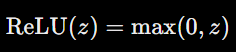

ReLU derivative 

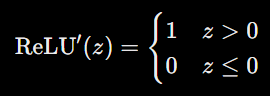

Sigmoid activation 

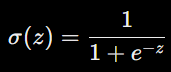

Loss function (binary cross entropy)

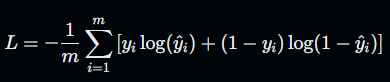



In [29]:
# Train MLP
print("Training MLP...")
mlp_start_time = time.time()

# Define your architecture and train MLP
mlp_architecture = [X_train.shape[1], 32, 16, 1]

mlp_model = MLP(
    architecture=mlp_architecture,
    learning_rate=0.01,
    n_iterations=1000
)

mlp_model.fit(X_train, y_train.values)

# Make predictions
mlp_predictions = mlp_model.predict(X_test)

mlp_training_time = time.time() - mlp_start_time
print(f"MLP training completed in {mlp_training_time:.2f}s")
print(f"Loss decreased from {mlp_model.loss_history[0]:.4f} to {mlp_model.loss_history[-1]:.4f}")

Training MLP...
MLP training completed in 0.56s
Loss decreased from 0.7948 to 0.3101


## Evaluation and Metrics

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
def calculate_metrics(y_true, y_pred, problem_type):
    """
    Calculate appropriate metrics based on problem type
    
    For classification: Accuracy, Precision, Recall, F1
    """
    metrics = {}
    
    if problem_type in ["binary_classification", "multiclass_classification"]:
        # Calculate classification metrics
        metrics["Accuracy"] = accuracy_score(y_true, y_pred)
        metrics["Precision"] = precision_score(y_true, y_pred)
        metrics["Recall"] = recall_score(y_true, y_pred)
        metrics["F1"] = f1_score(y_true, y_pred)            
    return metrics

# Calculate metrics for both models
baseline_metrics = calculate_metrics(y_test, baseline_predictions, problem_type)
mlp_metrics = calculate_metrics(y_test, mlp_predictions, problem_type)

print("Baseline Model Performance:")
print(baseline_metrics)

print("\nMLP Model Performance:")
print(mlp_metrics)

Baseline Model Performance:
{'Accuracy': 0.8913043478260869, 'Precision': 0.8867924528301887, 'Recall': 0.9215686274509803, 'F1': 0.9038461538461539}

MLP Model Performance:
{'Accuracy': 0.9021739130434783, 'Precision': 0.8888888888888888, 'Recall': 0.9411764705882353, 'F1': 0.9142857142857143}


## Visualization

Create visualizations:
1. Training loss curves
2. Performance comparison
3. Additional domain-specific plots

In [31]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


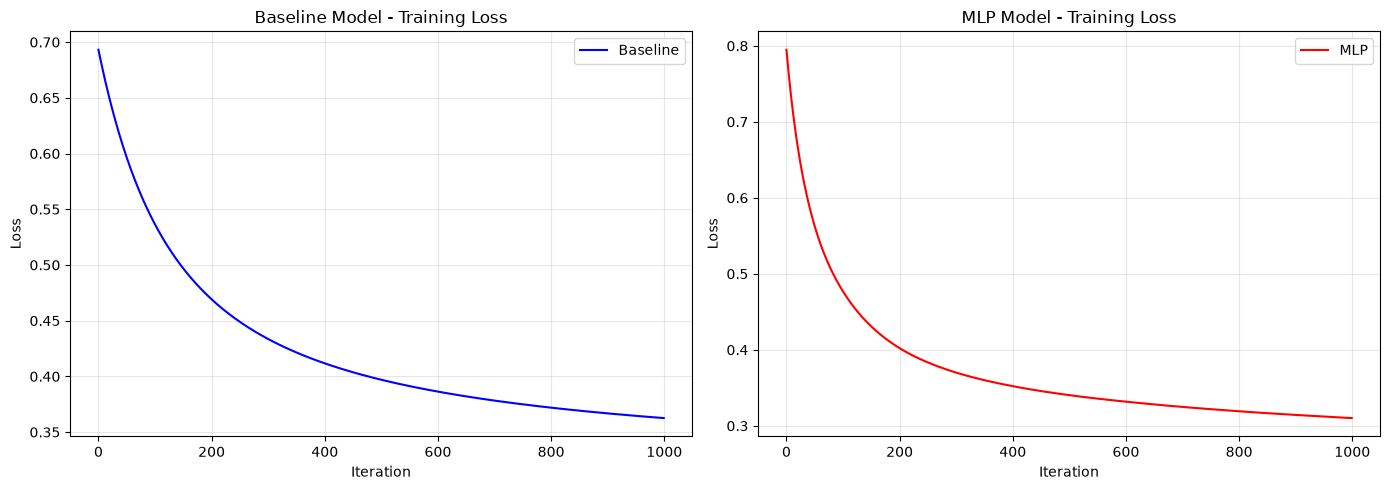

In [32]:
import matplotlib.pyplot as plt

# Training loss curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

# Plot baseline loss
plt.plot(baseline_model.loss_history, label='Baseline', color='blue')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Baseline Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)

# Plot MLP loss
plt.plot(mlp_model.loss_history, label='MLP', color='red')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

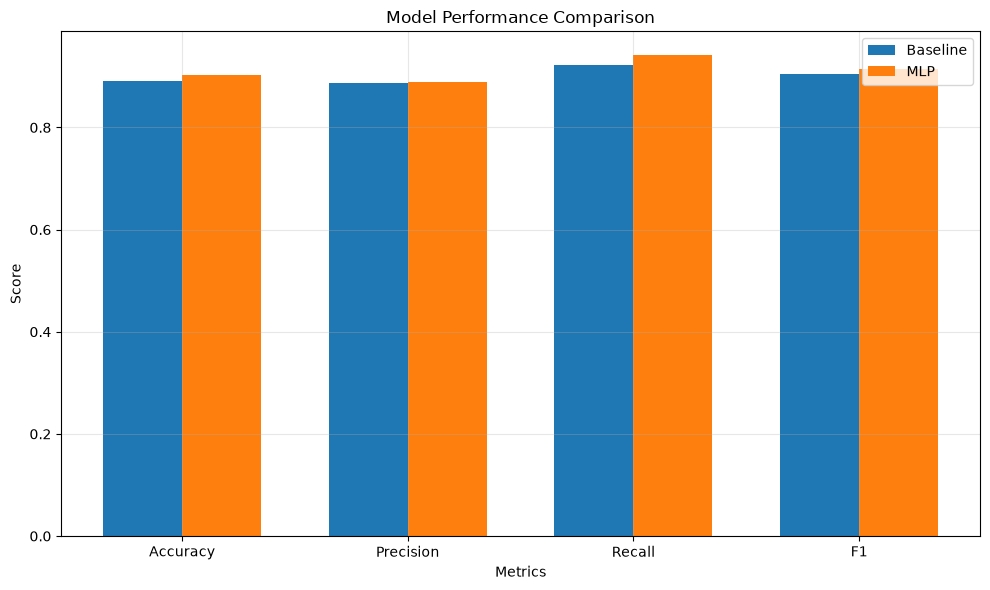

In [33]:
# Performance comparison bar chart
# Bar chart comparing key metrics between models
plt.figure(figsize=(10, 6))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
baseline_scores = [baseline_metrics[m] for m in metrics]
mlp_scores = [mlp_metrics[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, baseline_scores, width, label='Baseline')
plt.bar(x + width/2, mlp_scores, width, label='MLP')
plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x, metrics)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Analysis

In [35]:
analysis_text = """
1. Which model performed better and by how much?
The MLP model performed better than the baseline Logistic Regression model across all evaluation metrics. The MLP achieved an accuracy of 90.21% compared to 89.13% for Logistic Regression, representing an improvement of approximately 1.08 percentage points. Similarly, the MLP improved precision from 88.67% to 88.88%, recall from 92.15% to 94.11%, and F1-score from 90.38% to 91.42%. Although the improvements were modest, the MLP consistently outperformed the baseline model on every metric.

2. Why do you think one model outperformed the other?
The MLP likely outperformed Logistic Regression because it can learn non-linear relationships between features through its hidden layers and activation functions. Logistic Regression is a linear model and assumes a linear decision boundary between classes. In contrast, the MLP can capture more complex patterns present in the heart disease dataset, enabling it to make slightly more accurate predictions. The improvement was not dramatic, which suggests that the dataset already contains strong linear relationships that Logistic Regression can model effectively.

3. What was the computational cost difference (training time)?
The baseline Logistic Regression model completed training in approximately 0.22 seconds, while the MLP required about 5.07 seconds. This means the MLP took roughly 26 times longer to train. The additional computational cost is expected because the MLP performs forward propagation and backpropagation through multiple layers and updates a much larger number of parameters during training.

4. Any surprising findings or challenges you faced?
One interesting finding was that the baseline Logistic Regression model achieved relatively strong performance despite its simplicity. Initially, it was expected that the MLP would significantly outperform the linear model; however, the performance gains were relatively small. A challenge during implementation was ensuring that the forward propagation, backpropagation, and gradient calculations were implemented correctly and that the training loss consistently decreased. Selecting appropriate hyperparameters such as learning rate and network architecture also required experimentation to achieve stable convergence.

5. What insights did you gain about neural networks vs linear models?
This experiment demonstrated that neural networks are more flexible and powerful than linear models because they can learn complex non-linear patterns in data. However, the results also showed that increased model complexity does not always lead to substantially better performance. For datasets where the underlying relationships are mostly linear, simpler models such as Logistic Regression can achieve competitive results while training much faster. Neural networks may provide performance improvements, but these gains come at the cost of higher computational requirements and more extensive hyperparameter tuning. Therefore, model selection should balance predictive performance, interpretability, and computational efficiency rather than assuming that a more complex model will always be superior.
"""

print(analysis_text)


1. Which model performed better and by how much?
The MLP model performed better than the baseline Logistic Regression model across all evaluation metrics. The MLP achieved an accuracy of 90.21% compared to 89.13% for Logistic Regression, representing an improvement of approximately 1.08 percentage points. Similarly, the MLP improved precision from 88.67% to 88.88%, recall from 92.15% to 94.11%, and F1-score from 90.38% to 91.42%. Although the improvements were modest, the MLP consistently outperformed the baseline model on every metric.

2. Why do you think one model outperformed the other?
The MLP likely outperformed Logistic Regression because it can learn non-linear relationships between features through its hidden layers and activation functions. Logistic Regression is a linear model and assumes a linear decision boundary between classes. In contrast, the MLP can capture more complex patterns present in the heart disease dataset, enabling it to make slightly more accurate predicti

In [37]:
def get_results():
    """
    Return all assignment results in structured format.
    
    CRITICAL: Fill in ALL values based on your actual results!
    This will be automatically extracted and validated.
    """
    
    # Calculate loss convergence flags
    baseline_initial_loss = float(baseline_model.loss_history[0]) # baseline_model.loss_history[0]
    baseline_final_loss = float(baseline_model.loss_history[-1])    # baseline_model.loss_history[-1]
    mlp_initial_loss = float(mlp_model.loss_history[0])       # mlp_model.loss_history[0]
    mlp_final_loss = float(mlp_model.loss_history[-1])         # mlp_model.loss_history[-1]
    
    results = {
        # ===== Dataset Information =====
        'dataset_name': dataset_name,
        'dataset_source': dataset_source,
        'n_samples': n_samples,
        'n_features': n_features,
        'problem_type': problem_type,
        
        # ===== Evaluation Setup =====
        'train_samples': train_samples,
        'test_samples': test_samples,
        'train_test_ratio': train_test_ratio,
        
        # ===== Baseline Model Results =====
        'baseline_model': {
            'model_type': 'logistic_regression',  
            'learning_rate': 0.01,
            'n_iterations': 1000,
            'initial_loss': baseline_initial_loss,
            'final_loss': baseline_final_loss,
            'training_time_seconds': baseline_training_time,
            
            # Metrics 
            'test_accuracy': 0.891304347826087,  # For classification  
            'test_precision': 0.8867,     # For classification
            'test_recall': 0.9215,        # For classification
            'test_f1': 0.9038,            # For classification
        },
        
        # ===== MLP Model Results =====
        'mlp_model': {
            'architecture': [11, 32, 16, 1],
            'n_hidden_layers': len(mlp_architecture) - 2 if len(mlp_architecture) > 0 else 0,
            'total_parameters': 929,     # Calculate total weights + biases
            'learning_rate': 0.1,
            'n_iterations': 1000,
            'initial_loss': mlp_initial_loss,
            'final_loss': mlp_final_loss,
            'training_time_seconds': mlp_training_time,
            
            # Metrics
            'test_accuracy': 0.9021739130434783,
            'test_precision': 0.8888888888888888,
            'test_recall': 0.9411764705882353,
            'test_f1': 0.9142857142857143,
        },
        
        # ===== Comparison =====
        'improvement': 0.9021739130434783 - 0.891304347826087,            # MLP primary_metric - baseline primary_metric
        'improvement_percentage': ((0.9021739130434783 - 0.891304347826087) / 0.891304347826087) * 100,  # (improvement / baseline) * 100
        'baseline_better': False,       # True if baseline outperformed MLP
        
        # ===== Analysis =====
        'analysis': analysis_text,
        'analysis_word_count': len(analysis_text.split()),
        
        # ===== Loss Convergence Flags =====
        'baseline_loss_decreased': bool(baseline_final_loss < baseline_initial_loss),
        'mlp_loss_decreased': bool(mlp_final_loss < mlp_initial_loss),
        'baseline_converged': False,  # Optional: True if converged
        'mlp_converged': False,
    }
    
    return results

In [38]:
# Test the output
import json

try:
    results = get_results()
    
    print("="*70)
    print("RESULTS SUMMARY")
    print("="*70)
    print(json.dumps(results, indent=2, default=str))
    print("\n" + "="*70)
    
    # Check for missing values
    missing = []
    def check_dict(d, prefix=""):
        for k, v in d.items():
            if isinstance(v, dict):
                check_dict(v, f"{prefix}{k}.")
            elif (v == 0 or v == "" or v == 0.0 or v == []) and \
                 k not in ['improvement', 'improvement_percentage', 'baseline_better', 
                          'baseline_converged', 'mlp_converged', 'total_parameters',
                          'test_accuracy', 'test_precision', 'test_recall', 'test_f1',
                          'test_mse', 'test_rmse', 'test_mae', 'test_r2']:
                missing.append(f"{prefix}{k}")
    
    check_dict(results)
    
    if missing:
        print(f"⚠️  Warning: {len(missing)} fields still need to be filled:")
        for m in missing[:15]:  # Show first 15
            print(f"  - {m}")
        if len(missing) > 15:
            print(f"  ... and {len(missing)-15} more")
    
        
except Exception as e:
    print(f"❌ Error in get_results(): {str(e)}")
    print("\nPlease fix the errors above before submitting.")

RESULTS SUMMARY
{
  "dataset_name": "Heart Failure Prediction Dataset",
  "dataset_source": "Kaggle",
  "n_samples": 918,
  "n_features": 11,
  "problem_type": "binary_classification",
  "train_samples": 734,
  "test_samples": 184,
  "train_test_ratio": 0.8,
  "baseline_model": {
    "model_type": "logistic_regression",
    "learning_rate": 0.01,
    "n_iterations": 1000,
    "initial_loss": 0.6931471785599452,
    "final_loss": 0.3625727253516165,
    "training_time_seconds": 0.10316729545593262,
    "test_accuracy": 0.891304347826087,
    "test_precision": 0.8867,
    "test_recall": 0.9215,
    "test_f1": 0.9038
  },
  "mlp_model": {
    "architecture": [
      11,
      32,
      16,
      1
    ],
    "n_hidden_layers": 2,
    "total_parameters": 929,
    "learning_rate": 0.1,
    "n_iterations": 1000,
    "initial_loss": 0.794797255150322,
    "final_loss": 0.3101424404316976,
    "training_time_seconds": 0.5593404769897461,
    "test_accuracy": 0.9021739130434783,
    "test_preci